## 1. Import Libraries

In [9]:
import matplotlib.pyplot as plt
import torch
import tqdm
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

print("PyTorch version:", torch.__version__)
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("No GPU found, using CPU instead.")
    device = torch.device("cpu")

PyTorch version: 2.14.1+cpu
No GPU found, using CPU instead.


## 2. Data Loading

In [10]:
batch_size = 64
data_dir = "./data"

train_dataset = datasets.MNIST(data_dir, train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.MNIST(data_dir, train=False, transform=transforms.ToTensor())

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

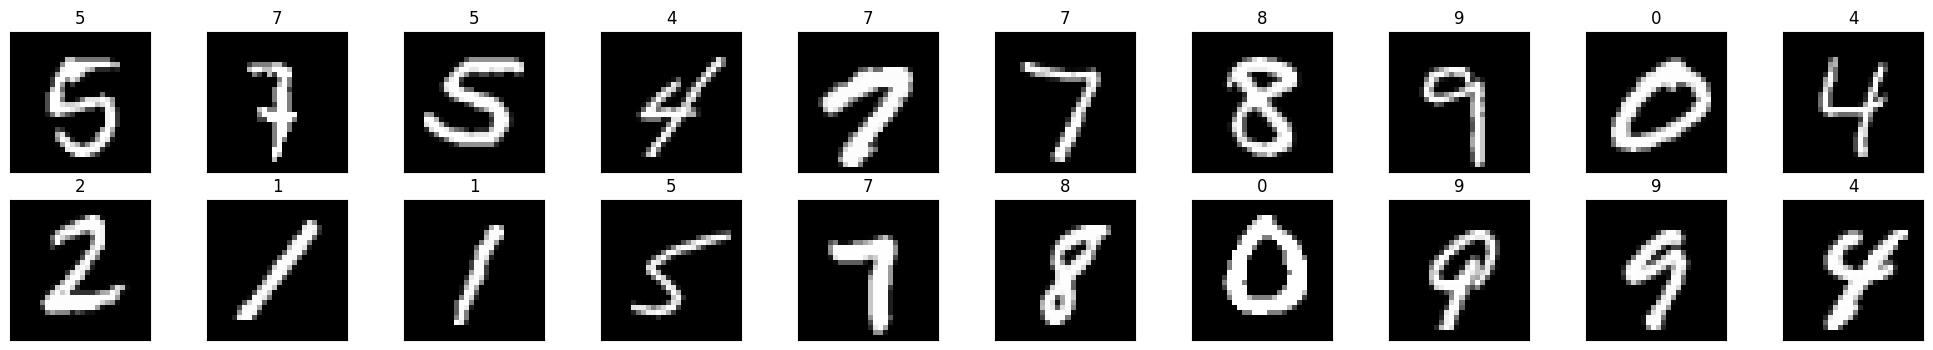

In [11]:
images, labels = next(iter(train_loader))
fig = plt.figure(figsize=(25, 4))

for idx in range(20):
    ax = fig.add_subplot(2, 20 // 2, idx + 1, xticks=[], yticks=[])
    ax.imshow(images[idx].squeeze(), cmap="gray")
    ax.set_title(str(labels[idx].item()))

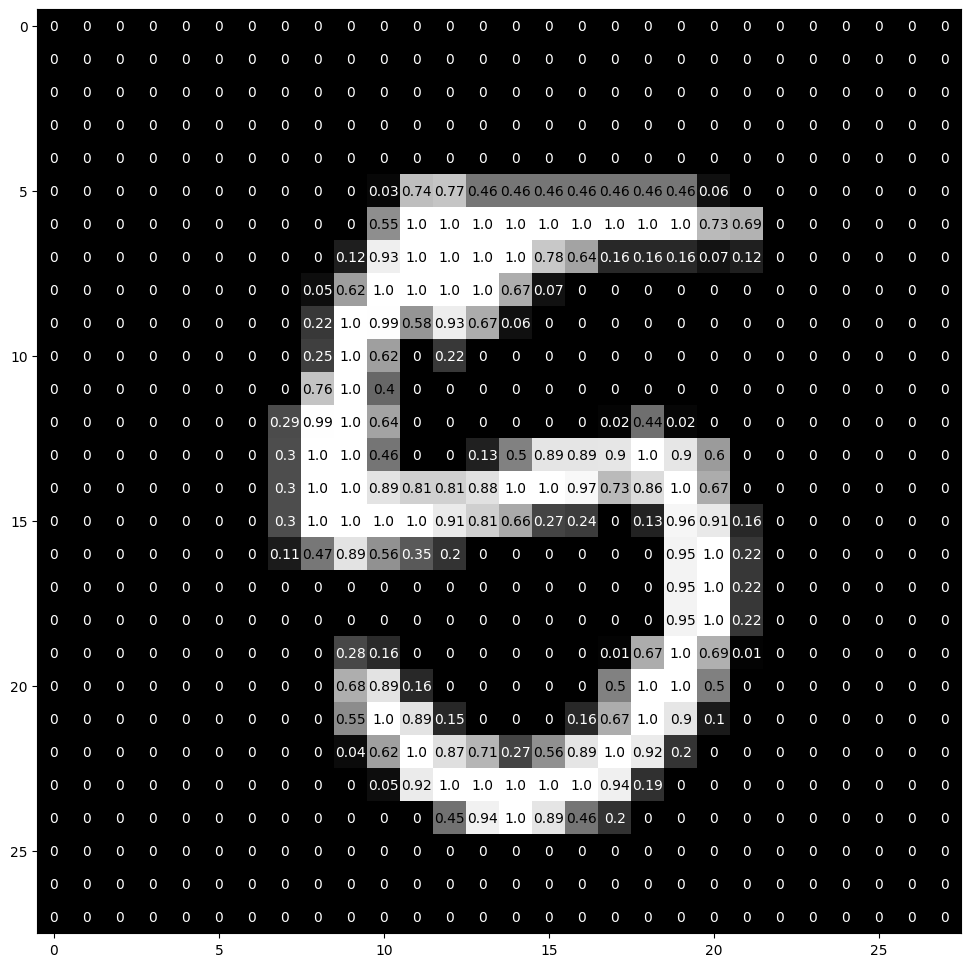

In [12]:
img = images[0].squeeze().numpy()

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111)
ax.imshow(img, cmap="gray")

width, height = img.shape
thresh = img.max() / 2.5

for x in range(width):
    for y in range(height):
        val = round(img[x][y], 2) if img[x][y] != 0 else 0
        ax.annotate(
            str(val),
            xy=(y, x),
            horizontalalignment="center",
            verticalalignment="center",
            color="white" if img[x][y] < thresh else "black",
        )

## 3. Model Definition

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flat1 = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        out = self.flat1(x)
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        return out

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.flat1 = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        out = self.conv1(x)
        out = self.relu1(out)
        out = self.pool1(out)
        
        out = self.conv2(out)
        out = self.relu2(out)
        out = self.pool2(out)

        out = self.flat1(out)
        out = self.fc1(out)
        out = self.relu3(out)

        out = self.fc2(out)
        return out

 ## 4. Model Initialization, Loss Function, and Optimizer


In [ ]:
model = CNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 5. Training Loop

In [ ]:
def train(
    data_loader: DataLoader,
    model: nn.Module,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer
):
    model.train()

    num_batches = len(data_loader)

    total_loss = 0.0
    total_correct_pred = 0
    # Iterate over all batches
    for images, labels in tqdm.tqdm(data_loader, total=num_batches):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        predicted = outputs.argmax(dim=1)
        total_loss += loss.item()
        total_correct_pred += (predicted == labels).sum().item()

    loss = total_loss / num_batches
    accuracy = total_correct_pred / len(data_loader.dataset)
    
    return loss, accuracy

In [ ]:
num_epochs = 10
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    loss, accuracy = train(train_loader, model, criterion, optimizer)

    train_losses.append(loss)
    train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{num_epochs}] -> Loss: {loss:.4f}, Accuracy: {100*accuracy:.2f}%")

100%|██████████| 938/938 [00:22<00:00, 42.06it/s]


Epoch [1/10] -> Loss: 0.1670, Accuracy: 94.90%


100%|██████████| 938/938 [00:23<00:00, 40.03it/s]


Epoch [2/10] -> Loss: 0.0499, Accuracy: 98.49%


100%|██████████| 938/938 [00:22<00:00, 40.88it/s]


...

Epoch [8/10] -> Loss: 0.0103, Accuracy: 99.66%


100%|██████████| 938/938 [00:23<00:00, 40.59it/s]


Epoch [9/10] -> Loss: 0.0099, Accuracy: 99.65%


100%|██████████| 938/938 [00:22<00:00, 42.45it/s]

Epoch [10/10] -> Loss: 0.0062, Accuracy: 99.78%


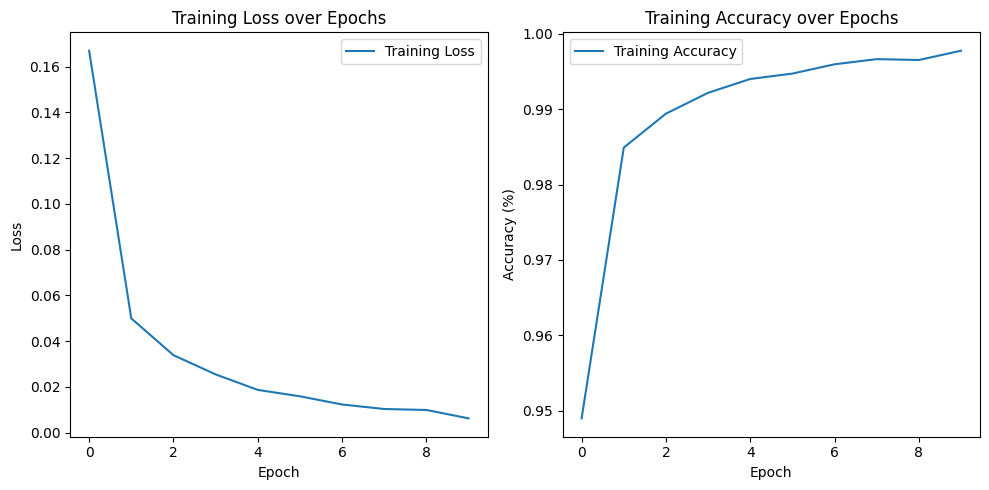

In [17]:
plt.figure(figsize=(10, 5))

# Plot training loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.legend()

# Plot training accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy over Epochs")
plt.legend()

plt.tight_layout()
plt.show()

## 6. Testing

In [18]:
def test(data_loader: DataLoader, model: nn.Module, criterion: nn.CrossEntropyLoss):
    model.eval()  # Set model to evaluation mode

    num_batches = len(data_loader)
    num_images = len(data_loader.dataset)

    total_loss = 0.0
    total_correct_pred = 0

    # Disable gradient computation for evaluation
    with torch.no_grad():

        # Iterate over all batches
        for images, labels in tqdm.tqdm(data_loader, total=num_batches):
            images = images.to(device)
            labels = labels.to(device)

            output = model(images)  # forward pass
            loss = criterion(output, labels)  # compute loss

            predicted = output.argmax(dim=1)  # get predicted labels
            total_loss += loss.item()
            total_correct_pred += (predicted == labels).sum().item()

    return total_loss / num_batches, total_correct_pred / num_images

In [19]:
loss, accuracy = test(test_loader, model, criterion)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {100*accuracy:.2f}%")

100%|██████████| 157/157 [00:02<00:00, 68.38it/s]

Test Loss: 0.0363, Test Accuracy: 98.98%
